In [9]:

# Lab Exercise 8: Naive Bayes Classification

from google.colab import files

uploaded = files.upload()

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import LabelEncoder

# Train-Test Split
from sklearn.model_selection import train_test_split

# Naive Bayes Classifier
from sklearn.naive_bayes import GaussianNB

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

Saving LengthOfStay.csv to LengthOfStay (2).csv
All libraries imported successfully!


In [10]:

# Loading the dataset
df = pd.read_csv("LengthOfStay.csv")

# Display first 5 rows
print("First 5 Rows of the Dataset")
display(df.head())

# Dataset Shape
print("\nDataset Shape:")
print(df.shape)

# Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset Information
print("\nDataset Information:")
df.info()

# Missing Values
print("\nMissing Values:")
display(df.isnull().sum())

First 5 Rows of the Dataset


,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3
1,2,5/26/2012,5+,F,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,6/2/2012,A,7
2,3,9/22/2012,1,F,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,9/25/2012,B,3
3,4,8/9/2012,0,F,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,8/10/2012,A,1
4,5,12/20/2012,0,F,0,0,0,1,0,1,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,12/24/2012,E,4



Dataset Shape:
(100000, 28)

Column Names:
['eid', 'vdate', 'rcount', 'gender', 'dialysisrenalendstage', 'asthma', 'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor', 'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo', 'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro', 'creatinine', 'bmi', 'pulse', 'respiration', 'secondarydiagnosisnonicd9', 'discharged', 'facid', 'lengthofstay']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  object 
 2   rcount                      100000 non-null  object 
 3   gender                      100000 non-null  object 
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma            

,0
eid,0
vdate,0
rcount,0
gender,0
dialysisrenalendstage,0
asthma,0
irondef,0
pneum,0
substancedependence,0
psychologicaldisordermajor,0


In [13]:

#  Data Preprocessing

# Remove duplicate records
df = df.drop_duplicates()

# Replace missing values (if any)
df.fillna(df.median(numeric_only=True), inplace=True)

# Convert 'rcount' to numeric, handling '5+'
df['rcount'] = df['rcount'].replace('5+', 5).astype(int)

# Select important features
features = [
    "rcount",
    "psychologicaldisordermajor",
    "hematocrit",
    "respiration",
    "bloodureanitro",
    "hemo",
    "sodium",
    "bmi",
    "glucose",
    "creatinine"
]

# Create target classes from Length of Stay
def classify_los(days):
    if days <= 3:
        return "Short Stay"
    elif days <= 7:
        return "Medium Stay"
    else:
        return "Long Stay"

df["LOS_Class"] = df["lengthofstay"].apply(classify_los)

# Encode target labels
label_encoder = LabelEncoder()
df["LOS_Class"] = label_encoder.fit_transform(df["LOS_Class"])

# Features and Target
X = df[features]
y = df["LOS_Class"]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(label_encoder.classes_)


Feature Matrix Shape: (100000, 10)
Target Shape: (100000,)

Target Classes:
['Long Stay' 'Medium Stay' 'Short Stay']


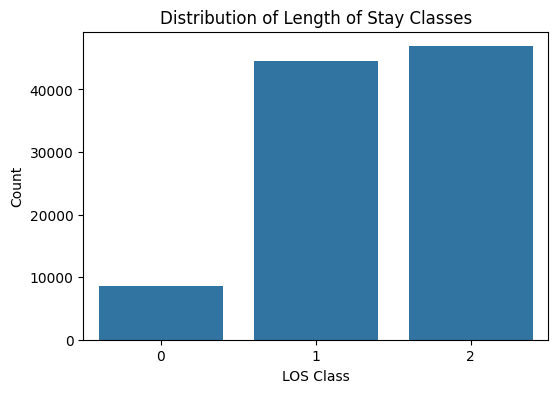

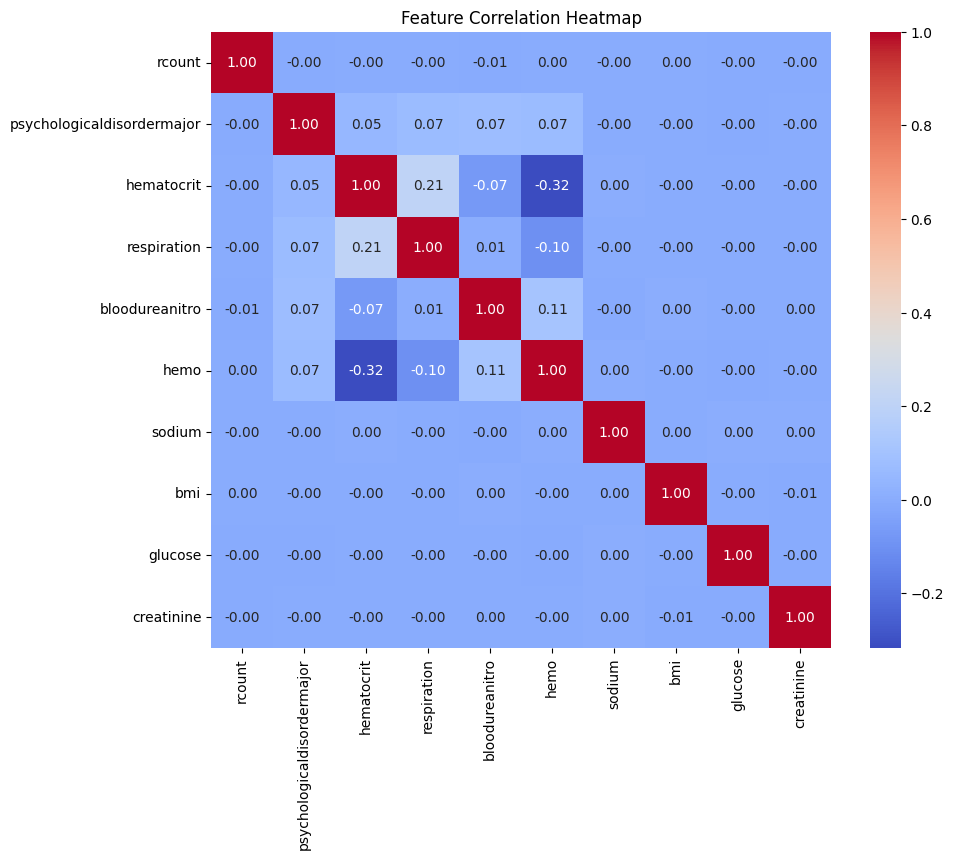

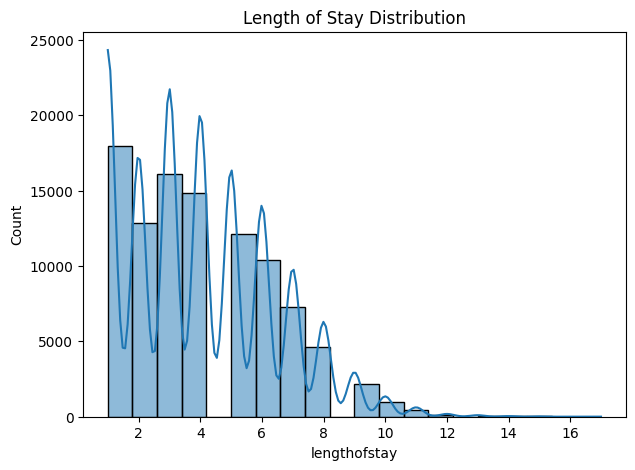

In [14]:

#Data Visualization

plt.figure(figsize=(6,4))
sns.countplot(x=df["LOS_Class"])
plt.title("Distribution of Length of Stay Classes")
plt.xlabel("LOS Class")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(10,8))
sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

plt.figure(figsize=(7,5))
sns.histplot(df["lengthofstay"], bins=20, kde=True)
plt.title("Length of Stay Distribution")
plt.show()

In [15]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

Training Samples : 80000
Testing Samples  : 20000


In [16]:
#Train Naive Bayes Model


model = GaussianNB()

model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [17]:
# Prediction
y_pred = model.predict(X_test)

print("Predicted Class Labels")
print(y_pred[:20])

Predicted Class Labels
[2 2 1 1 1 1 2 2 1 2 2 0 2 2 1 2 2 2 2 2]


In [18]:

#  Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Accuracy :", accuracy)

print("Precision :", precision)

print("Recall :", recall)

print("F1 Score :", f1)

print("\nClassification Report\n")

print(classification_report(y_test, y_pred))

Accuracy : 0.79175
Precision : 0.7877262065556521
Recall : 0.79175
F1 Score : 0.779705235214608

Classification Report

              precision    recall  f1-score   support

           0       0.73      0.31      0.43      1713
           1       0.79      0.74      0.76      8913
           2       0.80      0.93      0.86      9374

    accuracy                           0.79     20000
   macro avg       0.77      0.66      0.68     20000
weighted avg       0.79      0.79      0.78     20000



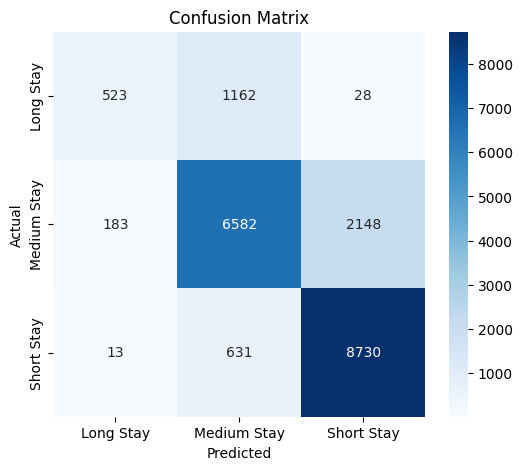

In [19]:

#  Confusion Matrix


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [20]:

#Predict New Patient

new_patient = pd.DataFrame([[
    1,
    0,
    40,
    18,
    15,
    13.5,
    140,
    24,
    100,
    1.0
]], columns=features)

prediction = model.predict(new_patient)

predicted_class = label_encoder.inverse_transform(prediction)

print("Predicted Class for New Patient :")

print(predicted_class[0])

Predicted Class for New Patient :
Long Stay


Interpretation

The Naive Bayes Classification algorithm was successfully implemented using the Hospital Length of Stay dataset. After preprocessing the data, the dataset was divided into training and testing sets. The Gaussian Naive Bayes classifier was trained and used to predict the Length of Stay category of unseen patients. The model's performance was evaluated using Accuracy, Precision, Recall, F1-Score, Classification Report and Confusion Matrix. The results demonstrate that Naive Bayes can effectively classify patient stay duration into different categories while providing fast and computationally efficient predictions.

Conclusion

This experiment successfully demonstrated the implementation of the Naive Bayes Classification algorithm on the Hospital Length of Stay dataset. The model was trained, evaluated and used to classify new patient records into Short Stay, Medium Stay or Long Stay categories. Various evaluation metrics confirmed the performance of the classifier, making it suitable for classification-based healthcare applications.

Self Learning

Through this experiment, I learned how to implement the Gaussian Naive Bayes Classification algorithm using Python. I understood the importance of preprocessing data, converting numerical targets into categorical classes, splitting data into training and testing sets, evaluating classification models using multiple performance metrics and interpreting the Confusion Matrix. I also learned how Naive Bayes uses probability to classify unseen instances efficiently.